# TechStock — fiabiliser un catalogue informatique

**Simulation pédagogique : données synthétiques.**

Le catalogue ERP compte 2 500 références ; les commandes web représentent 120 000 lignes sur trois ans. Des SKU correspondent à plusieurs produits, certaines lignes sont dupliquées et des quantités sont invalides. Le stock disponible ne décrit pas des réceptions complètes : une rotation exacte ne peut donc pas être affirmée.

## Objectif et démarche

Fiabiliser le chiffre d’affaires, identifier les références prioritaires et distinguer anomalies de données, prix atypiques légitimes et risques de stock.

- Combien de liaisons SKU sont non ambiguës ? Quelle part des ventes faut-il mettre à l’écart et quel impact cela a-t-il sur le périmètre mesuré ?
- Quels produits et catégories contribuent au CA, à la marge et à la concentration des ventes ?
- Le principe 80/20 est-il vérifié ? Quels seuils définissent les classes A, B et C et quelles références tombent à la frontière ?
- Quels prix sont atypiques après prise en compte de leur catégorie ? Un score robuste et un critère interquartile désignent-ils les mêmes références ?
- Quelles références cumulent forte contribution et faible couverture ? Quelles références de faible contribution immobilisent beaucoup de stock ?

Exécuter les cellules dans l’ordre. Les sources synthétiques sont régénérées avec une graine fixe ; les données réelles éventuelles nécessiteraient une étape de chargement distincte.

In [1]:
from pathlib import Path
import os, sqlite3, textwrap
os.environ.setdefault('OMP_NUM_THREADS', '2')
os.environ.setdefault('OPENBLAS_NUM_THREADS', '2')
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Markdown

# Retrouver le dossier du projet depuis sa racine ou le dossier notebooks.
ROOT = next(p for p in [Path.cwd(), Path.cwd().parent] if (p / 'data/raw').is_dir())
RAW, CLEAN, OUT, REPORT = [ROOT / p for p in ['data/raw', 'data/processed', 'analysis', 'reports']]
for directory in [RAW, CLEAN, OUT, REPORT, ROOT / 'docs']:
    directory.mkdir(parents=True, exist_ok=True)
RNG = np.random.default_rng(20261010)
AUDIT, DICT, FIGS, SECTIONS = [], [], [], []
plt.rcParams.update({'figure.figsize': (10, 4.8), 'axes.spines.top': False, 'axes.spines.right': False})


## Fonctions de qualité et de visualisation

Ces fonctions centralisent les exports CSV, la traçabilité des exclusions et les légendes des graphiques. Le bilan brut = doublons + rejets + propre est vérifié par assertion.

In [2]:
DEFAULT_UNITS = {'region': 'Région fictive', 'nom': 'Nom fictif', 'population': 'personnes', 'surface': 'm²', 'pieces': 'nombre de pièces', 'type': 'type de bien', 'date': 'ISO yyyy-MM-dd', 'prix': 'EUR/unité (transaction : EUR/bien)', 'nature': 'principal/annexe', 'categorie': 'catégorie produit', 'annee': 'année civile', 'kcal_kg': 'kcal/kg', 'production_t': 'tonnes/an', 'importations_t': 'tonnes/an', 'exportations_t': 'tonnes/an', 'variation_stock_t': 'tonnes/an, signe positif = apport au bilan', 'pertes_t': 'tonnes/an', 'alimentation_animale_t': 'tonnes/an', 'autres_usages_t': 'tonnes/an', 'cout': 'EUR/unité', 'stock_initial': 'unités, proxy de stock moyen', 'sku': 'identifiant web fictif', 'quantite': 'unités', 'remise': 'fraction, 0.10 = 10 %', 'retour': 'unités retournées', 'age': 'années', 'anciennete': 'années', 'segment': 'particulier/professionnel fictif', 'sexe': 'F/H, catégories simplifiées de la simulation', 'niveau': 'niveau de poste fictif', 'metier': 'famille métier fictive', 'site': 'site fictif', 'quotite': 'ETP contractuel, 0 < x <= 1', 'salaire_annuel_verse': 'EUR/an au temps contractuel', 'pays': 'territoire fictif', 'zone': 'Rural/Urbain', 'acces_sur_pct': 'pourcentage 0–100', 'budget_millions_eur': 'millions EUR', 'cout_beneficiaire_eur': 'EUR/personne', 'pib_habitant': 'USD fictifs/personne/an', 'conso_kg_hab': 'kg/personne/an', 'risque_logistique': 'score 0–100, élevé défavorable', 'croissance_pct': 'points de pourcentage annuel', 'est_faux': '1=faux simulé, 0=authentique simulé', 'diagonale': 'mm', 'hauteur_gauche': 'mm', 'hauteur_droite': 'mm', 'marge_haute': 'mm', 'marge_basse': 'mm', 'longueur': 'mm'}

def csv(df, file):
    df.to_csv(file, index=False, sep=';', encoding='utf-8-sig', float_format='%.8f')

def source(df, name, grain, units=None):
    csv(df, RAW / (name + '.csv'))
    for c in df:
        DICT.append({'table': name, 'grain': grain, 'colonne': c, 'type': str(df[c].dtype), 'unite_ou_sens': (units or {}).get(c, DEFAULT_UNITS.get(c, 'Identifiant fictif' if c.endswith('_id') else 'Voir énoncé et code de génération')), 'manquants': int(df[c].isna().sum())})

def clean(df, key, mask, name):
    dup = df.duplicated(key, keep='first')
    u = df.loc[~dup].copy()
    valid = mask(u).fillna(False)
    rejects = u.loc[~valid].copy()
    rejects['motif'] = 'Contrat de validation violé : voir les cellules de nettoyage du notebook'
    csv(df.loc[dup], OUT / (name + '_doublons.csv'))
    csv(rejects, OUT / (name + '_rejets.csv'))
    r = u.loc[valid].copy()
    AUDIT.append({'table': name, 'brut': len(df), 'doublons': int(dup.sum()), 'rejets': len(rejects), 'propre': len(r)})
    csv(r, CLEAN / (name + '.csv'))
    assert len(df) == int(dup.sum()) + len(rejects) + len(r)
    assert not r.duplicated(key).any()
    return r

FIGURE_LABELS = {'flux_stations': ('Solde des flux par station', 'Identifiant de station', 'Arrivées moins départs, locations'), 'ca_maintenance': ('Recettes et maintenance mensuelles', 'Mois', 'EUR'), 'prix_m2_annuel': ('Prix au m² — territoires fictifs', 'Année', 'Médiane des médianes communales, EUR/m²'), 'erreurs_prediction': ('Erreurs du modèle sur 2025', 'Prédiction moins prix réel, EUR', 'Nombre de ventes'), 'disponibilite_ponderee': ('Disponibilité calorique — bilans complets', 'Année', 'kcal/jour/personne, pondéré par population'), 'dependance_et_disponibilite': ('Dépendance aux importations et disponibilité', 'Importations / (production + importations)', 'Disponibilité, kcal/jour/personne'), 'distribution_prix': ('Distribution des prix catalogue', 'Logarithme naturel du prix en EUR', 'Nombre de références'), 'pareto_ca': ('Concentration du chiffre d’affaires', 'Fraction des références, par CA décroissant', 'Fraction cumulée du CA'), 'ca_et_marge_mensuels': ('Ventes et marge commerciale', 'Mois', 'EUR'), 'decomposition': ('Série mensuelle et décomposition STL', 'Mois', 'EUR'), 'validation_prevision': ('Prévision — six mois de test chronologique', 'Mois', 'Chiffre d’affaires net, EUR'), 'retention_cohortes': ('Rétention par cohorte — cellules futures non observées', 'Ancienneté en mois', 'Cohorte, ordre chronologique'), 'salaires_etp': ('Distribution des salaires normalisés ETP', 'Catégorie de sexe simulée', 'EUR/an équivalent temps plein'), 'ecarts_brut_ajuste': ('Écart salarial descriptif', 'Méthode', 'Écart en %, référence masculine'), 'besoin_regional': ('Population sans accès — données observées', 'Année', '% de la population observée'), 'stabilite_priorites': ('Sensibilité des priorités à la pondération', 'Identifiant du territoire fictif', 'Rang (1 = priorité maximale)'), 'acp_clusters': ('Segmentation des marchés fictifs — projection ACP', 'Composante principale 1, score standardisé', 'Composante principale 2, score standardisé'), 'choix_k': ('Sélection du nombre de clusters', 'Nombre de clusters k', 'Score silhouette'), 'stabilite': ('Stabilité du clustering, 30 sous-échantillons', 'ARI versus partition de référence', 'Nombre de réplications'), 'courbe_roc': ('Courbe ROC — défaut = classe positive', 'Taux de faux positifs', 'Taux de vrais positifs'), 'choix_seuil_validation': ('Sélection du seuil, données de validation', 'Seuil de probabilité', 'Coût conventionnel = 20 × FN + FP'), 'matrice_confusion': ('Matrice de confusion — jeu test', 'Classe prédite', 'Classe réelle')}

def figure(name, draw):
    fig, ax = plt.subplots()
    draw(ax)
    title, xlabel, ylabel = FIGURE_LABELS.get(name, (name.replace('_', ' ').capitalize(), '', ''))
    ax.set_title(title, pad=14)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    handles, legend = ax.get_legend_handles_labels()
    if handles:
        mapping = {'reel': 'Observé', 'ets': 'Prévision ETS', 'naif_saisonnier': 'Référence saisonnière', 'ca': 'CA net', 'marge': 'Marge commerciale', 'ca_net': 'CA net', 'tendance': 'Tendance STL', 'saisonnalite': 'Saisonnalité STL', 'rang_min': 'Rang minimal', 'rang_max': 'Rang maximal', 'kcal_ponderees': 'Disponibilité pondérée'}
        ax.legend(handles, [mapping.get(v, v) for v in legend], fontsize=9)
    if name in ['retention_cohortes', 'matrice_confusion'] and ax.images:
        fig.colorbar(ax.images[0], ax=ax, label='Taux de rétention' if name == 'retention_cohortes' else 'Nombre de pièces')
    if name == 'matrice_confusion':
        ax.set_xticks([0, 1], ['Conforme', 'Défaut'])
        ax.set_yticks([0, 1], ['Conforme', 'Défaut'])
        a = ax.images[0].get_array()
        for i in range(2):
            for j in range(2):
                ax.text(j, i, str(int(a[i, j])), ha='center', va='center', color='white' if a[i, j] > a.max() / 2 else 'black', fontsize=16)
    if name == 'acp_clusters' and ax.collections:
        fig.colorbar(ax.collections[0], ax=ax, label='Identifiant de cluster')
    fig.tight_layout()
    fig.savefig(REPORT / (name + '.png'), dpi=140)
    FIGS.append((name, fig))

def finish(title, question, metrics, tables, findings, actions, limits):
    """Exporter des résultats ouverts et préparer la restitution sans page web."""
    global METRICS, TITLE, QUESTION, FINDINGS, ACTIONS, LIMITS
    TITLE, QUESTION, METRICS = title, question, metrics
    FINDINGS, ACTIONS = findings, actions
    LIMITS = [s for s in limits if not any(w in s.lower() for w in ['natif', 'html', 'guide'])]
    csv(pd.DataFrame(AUDIT), OUT / 'qualite.csv')
    csv(pd.DataFrame(DICT), ROOT / 'docs/dictionnaire.csv')
    indicators = pd.DataFrame({'indicateur': metrics.keys(), 'valeur': list(metrics.values())})
    csv(indicators, OUT / 'indicateurs.csv')
    for name, table in tables.items():
        csv(table, OUT / (name + '.csv'))
    display(Markdown('## Résultats recalculés'))
    display(indicators)
    for item in findings:
        display(Markdown('- ' + item))
    from IPython.display import Image
    for name, fig in FIGS:
        display(Image(filename=str(REPORT / (name + '.png'))))
    plt.close('all')

class Restitution:
    """Relier les résultats calculés aux interprétations et aux recommandations."""
    def __init__(self):
        self.root = ROOT
        self.m = METRICS
        self.resume, self.actions = [], []
    def read(self, name):
        return pd.read_csv(ROOT / name, sep=';')
    def number(self, value, decimals=0):
        return f'{value:,.{decimals}f}'.replace(',', ' ').replace('.', ',')
    def pct(self, value, decimals=1):
        return self.number(value * 100, decimals) + ' %'
    def money(self, value, decimals=0):
        return self.number(value, decimals) + ' EUR'
    def section(self, title, paragraphs, tables=None):
        SECTIONS.append((title, paragraphs))
        display(Markdown('## ' + title + '\n\n' + '\n\n'.join(paragraphs)))
        for label, table in (tables or []):
            display(Markdown('### ' + label))
            display(table.head(30))


## Étape 1 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [3]:
import os

## Étape 2 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [4]:
os.environ.setdefault('OMP_NUM_THREADS', '2')

'2'

## Étape 3 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [5]:
os.environ.setdefault('OPENBLAS_NUM_THREADS', '2')

'2'

## Étape 4 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [6]:
npd, n = (2500, 120000)

## Étape 5 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [7]:
catalog = pd.DataFrame({'produit_id': np.arange(npd), 'categorie': RNG.choice(['Ordinateurs', 'Accessoires', 'Smartphones', 'Ecrans', 'Audio'], npd), 'prix': np.round(RNG.lognormal(5.3, 0.7, npd), 2), 'cout': np.round(RNG.uniform(20, 120, npd), 2), 'stock_initial': RNG.integers(30, 500, npd)})
catalog['cout'] = np.minimum(catalog.cout, catalog.prix * 0.75).round(2)
catalog.loc[:7, 'prix'] *= 12

## Étape 6 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [8]:
mapping = pd.DataFrame({'produit_id': np.arange(npd), 'sku': ['SKU' + str(i) for i in range(npd)]})
mapping.loc[:19, 'sku'] = mapping.loc[20:39, 'sku'].to_numpy()

## Étape 7 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [9]:
sales = pd.DataFrame({'ligne_id': np.arange(n), 'sku': ['SKU' + str(i) for i in RNG.integers(0, npd + 20, n)], 'date': (pd.Timestamp('2023-01-01') + pd.to_timedelta(RNG.integers(0, 1096, n), unit='D')).strftime('%Y-%m-%d'), 'quantite': RNG.integers(1, 6, n), 'remise': RNG.choice([0, 0.05, 0.1, 0.15], n)})

## Étape 8 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [10]:
sales.loc[:29, 'quantite'] = -1
sales = pd.concat([sales, sales.iloc[400:520]], ignore_index=True)

## Étape 9 — Documenter les données simulées

Les tables sources sont enregistrées en CSV avec leur grain, leurs unités et les valeurs manquantes. La graine fixe rend la simulation reproductible.

In [11]:
source(catalog, 'erp', 'produit', {'prix': 'EUR/unité', 'cout': 'EUR/unité', 'stock_initial': 'unités'})
source(mapping, 'liaison', 'produit-SKU')
source(sales, 'web', 'ligne de commande')

## Étape 10 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [12]:
amb = mapping[mapping.duplicated('sku', keep=False)]
csv(amb, OUT / 'liaisons_ambigues.csv')
safe = mapping[~mapping.sku.isin(amb.sku)]

## Étape 11 — Contrôler et rapprocher les tables

Les clés et les règles de validité protègent le grain des données. Les exclusions sont tracées et les jointures sont contrôlées avant les calculs.

In [13]:
v = clean(sales, 'ligne_id', lambda x: x.quantite.gt(0) & x.sku.isin(safe.sku) & pd.to_datetime(x.date, errors='coerce').notna(), 'ventes')
v = v.merge(safe, on='sku', validate='many_to_one').merge(catalog, on='produit_id', validate='many_to_one')
v['ca'] = np.round(v.quantite * v.prix * (1 - v.remise), 2)
v['marge'] = v.ca - v.quantite * v.cout
csv(v, CLEAN / 'ventes_enrichies.csv')

## Étape 12 — Contrôler et rapprocher les tables

Les clés et les règles de validité protègent le grain des données. Les exclusions sont tracées et les jointures sont contrôlées avant les calculs.

In [14]:
agg = v.groupby('produit_id').agg(ca=('ca', 'sum'), marge=('marge', 'sum'), unites=('quantite', 'sum')).reset_index().merge(catalog, on='produit_id', validate='one_to_one').sort_values('ca', ascending=False)
agg['part_cumulee'] = agg.ca.cumsum() / agg.ca.sum()
agg['abc'] = np.where(agg.part_cumulee.le(0.8), 'A', np.where(agg.part_cumulee.le(0.95), 'B', 'C'))
agg['stock_couverture_mois'] = agg.stock_initial / (agg.unites / 36)
agg['rotation_annuelle_proxy'] = agg.unites / 3 / agg.stock_initial

## Étape 13 — Calculer les indicateurs

Les agrégations conservent les dimensions de comparaison et les dénominateurs explicites. Les résultats intermédiaires alimentent la restitution.

In [15]:
catalog['logprix'] = np.log(catalog.prix)
med = catalog.groupby('categorie').logprix.transform('median')
mad = catalog.groupby('categorie').logprix.transform(lambda x: np.median(abs(x - x.median())))
catalog['score_mad'] = 0.67449 * (catalog.logprix - med) / mad
outliers = catalog[catalog.score_mad.abs() > 3.5]

## Étape 14 — Calculer les indicateurs

Les agrégations conservent les dimensions de comparaison et les dénominateurs explicites. Les résultats intermédiaires alimentent la restitution.

In [16]:
monthly = v.assign(mois=v.date.str[:7]).groupby('mois').agg(ca=('ca', 'sum'), marge=('marge', 'sum')).reset_index()

## Étape 15 — Visualiser les résultats

Les graphiques décrivent les variables et les comparaisons calculées dans les cellules précédentes. Les axes et leurs unités sont explicités.

In [17]:
figure('distribution_prix', lambda ax: ax.hist(catalog.logprix, bins=45))
figure('pareto_ca', lambda ax: ax.plot(np.arange(1, len(agg) + 1) / len(agg), agg.part_cumulee))
figure('ca_et_marge_mensuels', lambda ax: monthly.plot(x='mois', y=['ca', 'marge'], ax=ax, rot=65))

## Étape 16 — Restituer les résultats

Les indicateurs et les tableaux sont exportés en CSV ; les conclusions et les limites sont conservées pour la présentation.

## Résultats recalculés

          indicateur       valeur
0     lignes_valides    117080.00
1  liaisons_ambigues        40.00
2             ca_net  83890298.06
3  marge_commerciale  61175149.94
4     prix_atypiques         6.00
5  produits_classe_A      1351.00

- 40 liaisons ambiguës exclues avant jointure pour éviter une multiplication des ventes.

- 6 prix atypiques détectés sur log-prix par catégorie, signalés et conservés.

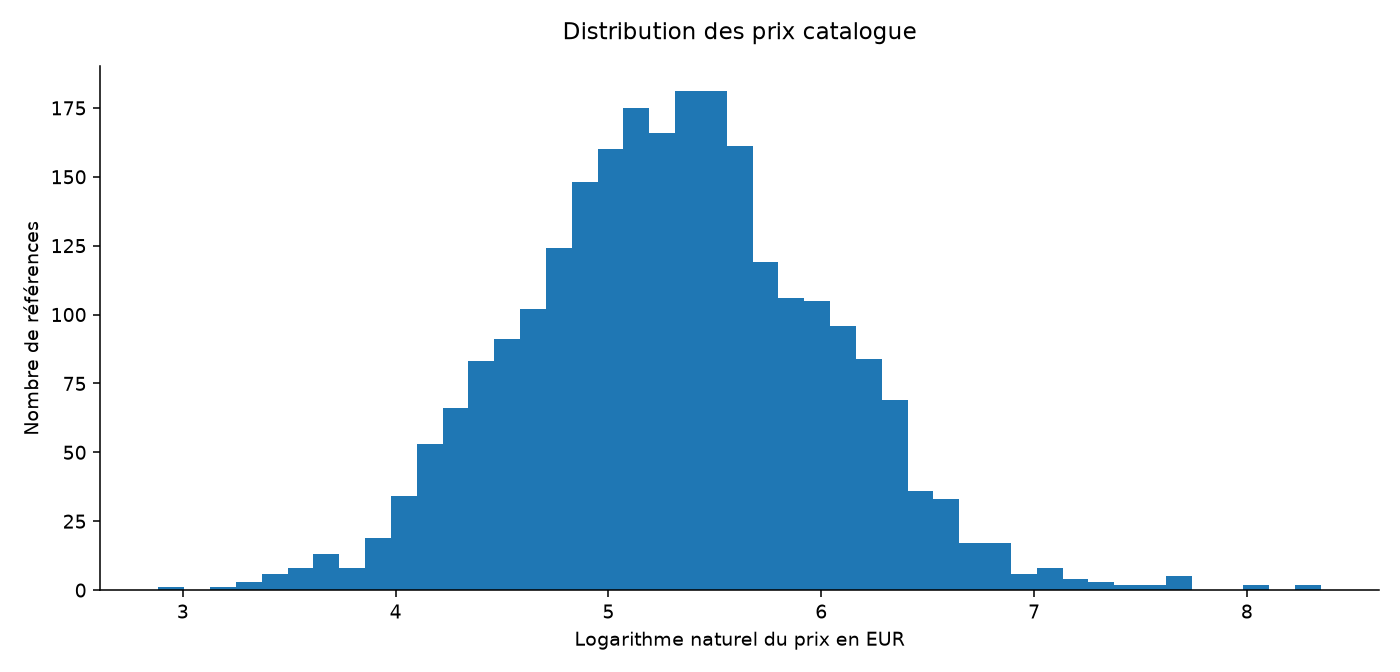

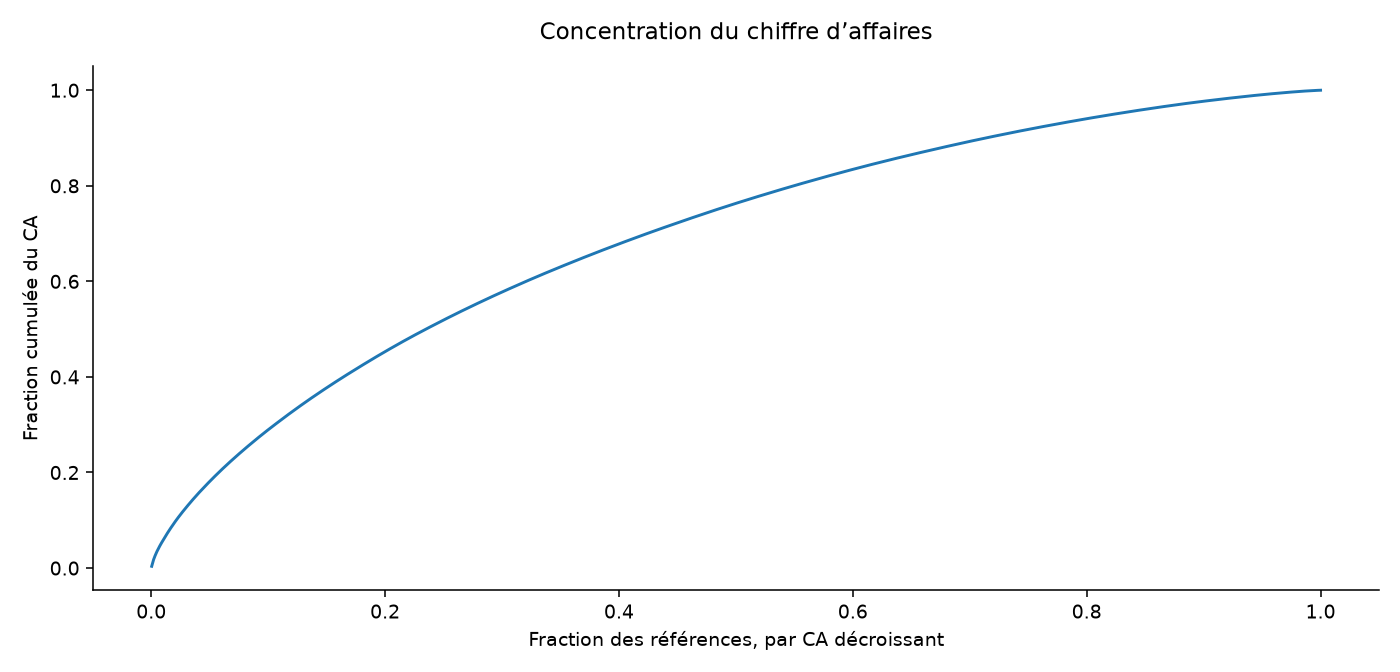

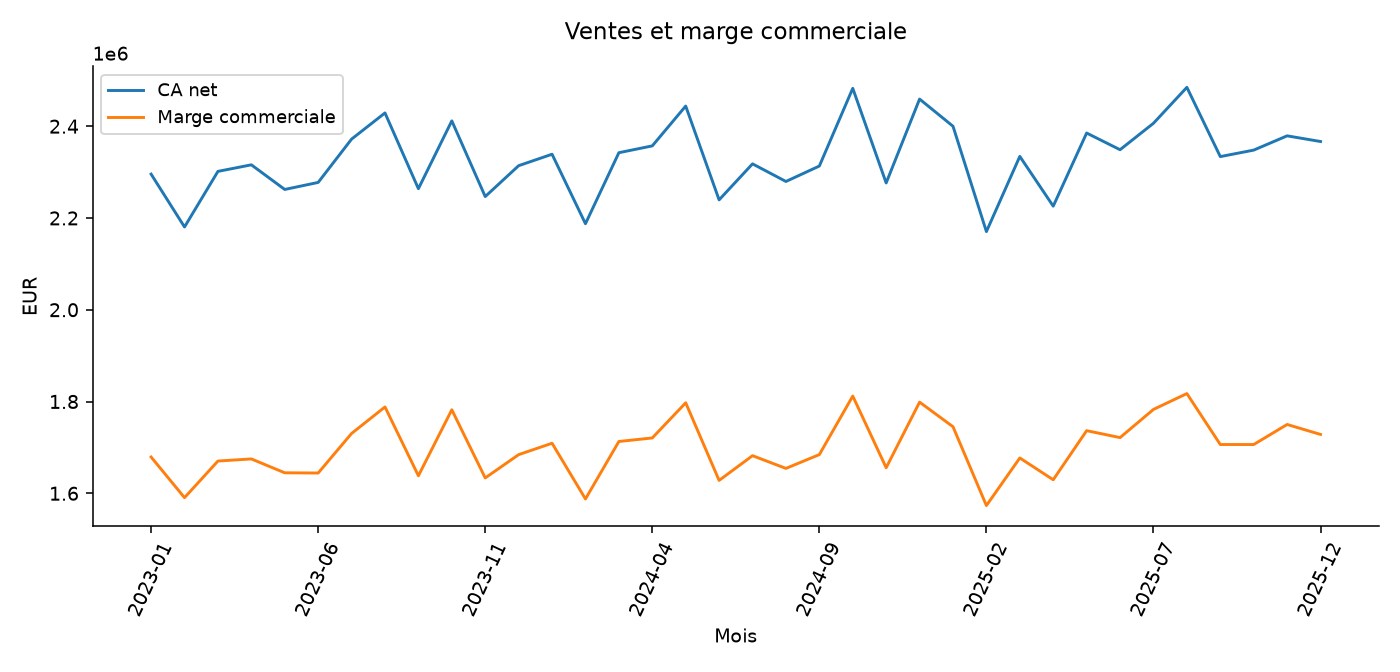

In [18]:
finish('TechStock — qualité, catalogue et stock', 'Fiabiliser ERP/web et identifier les références à surveiller.', {'lignes_valides': len(v), 'liaisons_ambigues': len(amb), 'ca_net': v.ca.sum(), 'marge_commerciale': v.marge.sum(), 'prix_atypiques': len(outliers), 'produits_classe_A': int(agg.abc.eq('A').sum())}, {'produits_abc_stock': agg, 'prix_a_investiguer': outliers, 'mensuel': monthly}, [f'{len(amb)} liaisons ambiguës exclues avant jointure pour éviter une multiplication des ventes.', f'{len(outliers)} prix atypiques détectés sur log-prix par catégorie, signalés et conservés.'], ['Résoudre les SKU ambigus avec le référentiel métier.', 'Prioriser les références A et examiner les couvertures longues.'], ['Prix extrêmes potentiellement légitimes : pas de suppression automatique.', 'Stock initial comme proxy : rotation comptable impossible sans stock moyen et réceptions.', 'Données fictives, marge hors frais fixes et logistique.'])

In [19]:
import pandas as pd, numpy as np

## Analyse approfondie et interprétation

Les calculs suivants relisent les CSV produits par ce notebook et les confrontent aux hypothèses métier. Les tableaux affichés sont limités à trente lignes ; les exports CSV restent complets.

In [20]:
r = Restitution()

In [21]:
m = r.m

In [22]:
n = r.number

In [23]:
p = r.pct

In [24]:
e = r.money

In [25]:
v = r.read('data/processed/ventes_enrichies.csv')

In [26]:
a = r.read('analysis/produits_abc_stock.csv')

In [27]:
out = r.read('analysis/prix_a_investiguer.csv')

In [28]:
mo = r.read('analysis/mensuel.csv')

In [29]:
catalog = r.read('data/raw/erp.csv')

In [30]:
amb = r.read('analysis/liaisons_ambigues.csv')

In [31]:
cat = v.groupby('categorie').agg(ca=('ca', 'sum'), marge=('marge', 'sum'), unites=('quantite', 'sum'), references=('produit_id', 'nunique')).reset_index()

In [32]:
cat['taux_marque'] = cat.marge / cat.ca

In [33]:
cat['part_ca'] = cat.ca / cat.ca.sum()

In [34]:
abc = a.groupby('abc').agg(references=('produit_id', 'size'), ca=('ca', 'sum'), marge=('marge', 'sum'), stock=('stock_initial', 'sum')).reset_index()

In [35]:
abc['part_references'] = abc.references / len(a)

In [36]:
abc['part_ca'] = abc.ca / abc.ca.sum()

In [37]:
top20 = a.sort_values('ca', ascending=False).head(int(np.ceil(0.2 * len(a)))).ca.sum() / a.ca.sum()

In [38]:
quant = catalog.groupby('categorie').prix.quantile([0.25, 0.5, 0.75]).unstack().reset_index()

In [39]:
quant.columns = ['categorie', 'q1', 'mediane', 'q3']

In [40]:
cc = catalog.merge(quant, on='categorie', validate='many_to_one')

In [41]:
cc['iqr'] = cc.q3 - cc.q1

In [42]:
ii = cc[(cc.prix < cc.q1 - 1.5 * cc.iqr) | (cc.prix > cc.q3 + 1.5 * cc.iqr)]

In [43]:
both = len(set(ii.produit_id) & set(out.produit_id))

In [44]:
a['stock_valorise_cout'] = a.stock_initial * a.cout

In [45]:
stock = a.groupby('abc').agg(stock_valorise=('stock_valorise_cout', 'sum'), couverture_mediane=('stock_couverture_mois', 'median'), references=('produit_id', 'size')).reset_index()

In [46]:
slow = a[a.stock_couverture_mois.gt(12)].sort_values('stock_valorise_cout', ascending=False).head(12)[['produit_id', 'categorie', 'abc', 'ca', 'stock_valorise_cout', 'stock_couverture_mois']]

In [47]:
v['annee'] = v.date.str[:4]

In [48]:
annual = v.groupby('annee').agg(ca=('ca', 'sum'), marge=('marge', 'sum'), unites=('quantite', 'sum')).reset_index()

In [49]:
annual['taux_marque'] = annual.marge / annual.ca

In [50]:
r.resume = [f"TechStock rapproche un catalogue de 2 500 produits informatiques et conserve {n(m['lignes_valides'], 0)} lignes web valides. Les {m['liaisons_ambigues']} liaisons ambiguës restent exclues tant que le référentiel n’est pas corrigé.", f"Le périmètre valide produit {e(m['ca_net'])} de CA après remises et {e(m['marge_commerciale'])} de marge commerciale, soit un taux de marque de {p(m['marge_commerciale'] / m['ca_net'], 1)}.", f'Les 20 % de références les plus contributrices réalisent {p(top20, 1)} du CA ; l’expression 80/20 ne doit donc pas être répétée sans vérification.', f'Le détecteur MAD signale {len(out)} prix à investiguer ; le critère IQR en signale {len(ii)}. La couverture calculée sur un stock initial reste un proxy, pas un indicateur exact de rotation.']

In [51]:
r.section('4. Réconcilier les identifiants avant les montants', ['L’ERP décrit les produits et leurs prix/coûts ; la table de liaison associe produit_id à un SKU web. Avant de joindre les ventes, les SKU présents sur plusieurs produits sont identifiés et isolés. Les attribuer au premier produit rencontré serait une réparation arbitraire.', f'Le contrôle trouve {len(amb)} lignes de liaison ambiguës, correspondant à {amb.sku.nunique()} SKU distincts. Leur exclusion peut aussi retirer des ventes par ailleurs valides. Le CA publié est donc celui du sous-périmètre rapproché, pas le CA exhaustif du commerce.', f'Après contrôle du grain ligne_id et des quantités, {n(len(v), 0)} lignes restent analysables. La jointure enrichie conserve exactement ce nombre et une seule occurrence de ligne_id. La somme des recettes se réconcilie avec la somme par produit et par catégorie.', 'Le CA de ligne est quantité × prix catalogue × (1 − remise), arrondi au centime avec l’arrondi numérique de référence de la simulation. La marge de ligne est ce CA moins quantité × coût unitaire. Il n’y a ni retours, ni TVA, ni frais logistiques dans ce scénario ; le qualificatif marge commerciale évite une confusion avec le résultat net.'], [('Évolution annuelle sur périmètre valide', annual)])

## 4. Réconcilier les identifiants avant les montants

L’ERP décrit les produits et leurs prix/coûts ; la table de liaison associe produit_id à un SKU web. Avant de joindre les ventes, les SKU présents sur plusieurs produits sont identifiés et isolés. Les attribuer au premier produit rencontré serait une réparation arbitraire.

Le contrôle trouve 40 lignes de liaison ambiguës, correspondant à 20 SKU distincts. Leur exclusion peut aussi retirer des ventes par ailleurs valides. Le CA publié est donc celui du sous-périmètre rapproché, pas le CA exhaustif du commerce.

Après contrôle du grain ligne_id et des quantités, 117 080 lignes restent analysables. La jointure enrichie conserve exactement ce nombre et une seule occurrence de ligne_id. La somme des recettes se réconcilie avec la somme par produit et par catégorie.

Le CA de ligne est quantité × prix catalogue × (1 − remise), arrondi au centime avec l’arrondi numérique de référence de la simulation. La marge de ligne est ce CA moins quantité × coût unitaire. Il n’y a ni retours, ni TVA, ni frais logistiques dans ce scénario ; le qualificatif marge commerciale évite une confusion avec le résultat net.

### Évolution annuelle sur périmètre valide

  annee           ca        marge  unites  taux_marque
0  2023  27669806.41  20159658.38  116432     0.728580
1  2024  28037912.79  20442192.59  117524     0.729091
2  2025  28182578.86  20573298.97  117873     0.730001

In [52]:
r.section('5. Séparer contribution, rentabilité et volume', [f'Le taux de marque global est {p(v.marge.sum() / v.ca.sum(), 2)}. Il est calculé comme somme des marges / somme des CA. Une moyenne simple des taux de produits surpondérerait les petites références et pourrait donner une lecture différente sans changement économique.', 'Les catégories sont comparées sur quatre axes : recettes, marge, unités et nombre de références vendues. La catégorie qui réalise le plus de CA n’est pas nécessairement celle qui apporte la meilleure marge par euro vendu ou par référence.', f'Les recettes mensuelles s’étendent de {e(mo.ca.min())} à {e(mo.ca.max())}. Les différences restent descriptives : le générateur n’inclut pas de campagnes, d’acquisitions de clients ou de coûts de canal permettant une explication causale.', 'Avant toute recommandation sur l’assortiment, il faudrait intégrer les délais d’approvisionnement, la compatibilité des accessoires, les effets de vente croisée et la garantie. Une lecture uniquement par marge directe peut sous-estimer une référence servant de produit d’appel.'], [('Contribution des catégories', cat)])

## 5. Séparer contribution, rentabilité et volume

Le taux de marque global est 72,92 %. Il est calculé comme somme des marges / somme des CA. Une moyenne simple des taux de produits surpondérerait les petites références et pourrait donner une lecture différente sans changement économique.

Les catégories sont comparées sur quatre axes : recettes, marge, unités et nombre de références vendues. La catégorie qui réalise le plus de CA n’est pas nécessairement celle qui apporte la meilleure marge par euro vendu ou par référence.

Les recettes mensuelles s’étendent de 2 170 350 EUR à 2 484 724 EUR. Les différences restent descriptives : le générateur n’inclut pas de campagnes, d’acquisitions de clients ou de coûts de canal permettant une explication causale.

Avant toute recommandation sur l’assortiment, il faudrait intégrer les délais d’approvisionnement, la compatibilité des accessoires, les effets de vente croisée et la garantie. Une lecture uniquement par marge directe peut sous-estimer une référence servant de produit d’appel.

### Contribution des catégories

     categorie           ca        marge  unites  references  taux_marque  \
0  Accessoires  18086673.30  13275196.22   76332         538     0.733977   
1        Audio  15722626.51  11217235.29   66512         463     0.713445   
2       Ecrans  16554749.77  12051074.72   68543         482     0.727953   
3  Ordinateurs  15492614.05  11228988.33   67391         473     0.724796   
4  Smartphones  18033634.43  13402655.38   73051         504     0.743203   

    part_ca  
0  0.215599  
1  0.187419  
2  0.197338  
3  0.184677  
4  0.214967  

In [53]:
r.section('6. Tester la concentration et construire les classes ABC', [f'Les 20 % de références les mieux classées représentent {p(top20, 1)} du CA. Une règle de Pareto est ici une hypothèse de concentration à vérifier, pas une propriété automatique d’un catalogue.', 'Les produits sont ordonnés par CA décroissant puis cumulés. Le code affecte A aux lignes dont la part cumulée est <= 80 %, B jusqu’à 95 %, C au-delà. La référence qui fait franchir la frontière appartient donc à la classe suivante ; cette convention est explicite et peut faire terminer A légèrement avant 80 %.', f"La classe A contient {int(abc.loc[abc.abc.eq('A'), 'references'].iloc[0])} références sur {len(a)} vendues. Ce nombre renseigne l’effort de supervision nécessaire : si A représente une grande fraction du catalogue, un pilotage limité à quelques produits ne couvre pas l’essentiel des recettes.", 'Le classement est fondé sur le CA, pas sur la marge. Une variante par marge pourrait changer les priorités. Il convient de comparer les deux lorsque l’objectif du décideur porte sur la contribution économique plutôt que sur le volume d’affaires.'], [('Bilan ABC', abc)])

## 6. Tester la concentration et construire les classes ABC

Les 20 % de références les mieux classées représentent 45,3 % du CA. Une règle de Pareto est ici une hypothèse de concentration à vérifier, pas une propriété automatique d’un catalogue.

Les produits sont ordonnés par CA décroissant puis cumulés. Le code affecte A aux lignes dont la part cumulée est <= 80 %, B jusqu’à 95 %, C au-delà. La référence qui fait franchir la frontière appartient donc à la classe suivante ; cette convention est explicite et peut faire terminer A légèrement avant 80 %.

La classe A contient 1351 références sur 2460 vendues. Ce nombre renseigne l’effort de supervision nécessaire : si A représente une grande fraction du catalogue, un pilotage limité à quelques produits ne couvre pas l’essentiel des recettes.

Le classement est fondé sur le CA, pas sur la marge. Une variante par marge pourrait changer les priorités. Il convient de comparer les deux lorsque l’objectif du décideur porte sur la contribution économique plutôt que sur le volume d’affaires.

### Bilan ABC

  abc  references           ca        marge   stock  part_references   part_ca
0   A        1351  67095650.93  53468475.19  357443         0.549187  0.799802
1   B         674  12587156.77   6402515.80  176064         0.273984  0.150043
2   C         435   4207490.36   1304158.95  112259         0.176829  0.050155

In [54]:
r.section('7. Investiguer les prix sans supprimer des produits légitimes', [f'Le détecteur robuste calcule le log-prix, sa médiane par catégorie, puis le score 0,67449 × écart à la médiane / MAD. Le seuil absolu 3,5 signale {len(out)} références. Il ne prouve pas qu’un prix est faux.', f'Un second critère basé sur les quartiles des prix non transformés signale {len(ii)} références ; {both} apparaissent dans les deux listes. Les ensembles diffèrent car la transformation logarithmique, la dispersion et la forme des distributions ne sont pas identiques.', 'Sur des prix asymétriques, l’IQR en échelle brute peut signaler beaucoup de produits premium. Le contrôle par catégorie limite les comparaisons incohérentes entre, par exemple, un accessoire et un ordinateur. Un produit extrême doit être vérifié dans le catalogue, le fournisseur et l’historique avant correction.', 'Le traitement retenu est de conserver les ventes des références atypiques tout en fournissant une liste d’investigation. Cette décision évite de réduire artificiellement les recettes en supprimant les produits chers sous couvert de nettoyage.'], [('Quantiles de prix par catégorie', quant), ('Références signalées MAD', out[['produit_id', 'categorie', 'prix', 'score_mad']])])

## 7. Investiguer les prix sans supprimer des produits légitimes

Le détecteur robuste calcule le log-prix, sa médiane par catégorie, puis le score 0,67449 × écart à la médiane / MAD. Le seuil absolu 3,5 signale 6 références. Il ne prouve pas qu’un prix est faux.

Un second critère basé sur les quartiles des prix non transformés signale 140 références ; 5 apparaissent dans les deux listes. Les ensembles diffèrent car la transformation logarithmique, la dispersion et la forme des distributions ne sont pas identiques.

Sur des prix asymétriques, l’IQR en échelle brute peut signaler beaucoup de produits premium. Le contrôle par catégorie limite les comparaisons incohérentes entre, par exemple, un accessoire et un ordinateur. Un produit extrême doit être vérifié dans le catalogue, le fournisseur et l’historique avant correction.

Le traitement retenu est de conserver les ventes des références atypiques tout en fournissant une liste d’investigation. Cette décision évite de réduire artificiellement les recettes en supprimant les produits chers sous couvert de nettoyage.

### Quantiles de prix par catégorie

     categorie        q1  mediane        q3
0  Accessoires  121.9900  203.680  311.0900
1        Audio  134.9200  208.030  321.3350
2       Ecrans  127.4825  191.610  312.6200
3  Ordinateurs  123.6950  196.180  332.3575
4  Smartphones  124.8675  209.205  322.7525

### Références signalées MAD

   produit_id    categorie     prix  score_mad
0           0  Accessoires  4220.88   4.334839
1           1        Audio  2174.64   3.624771
2           2  Accessoires  3215.76   3.945894
3           3  Ordinateurs  3983.76   4.168449
4           4  Ordinateurs  3302.04   3.908611
5        2177       Ecrans    17.91  -3.597983

In [55]:
r.section('8. Stock : transformer un proxy en question de collecte', [f'La couverture simulée est stock initial / (unités vendues sur 36 mois / 36). {int(a.stock_couverture_mois.gt(12).sum())} références ont une couverture supérieure à douze mois. Le stock valorisé au coût sur le périmètre vendu vaut {e(a.stock_valorise_cout.sum())}.', 'Ces valeurs supposent un rythme moyen constant et utilisent le stock initial comme s’il était disponible à la date d’analyse. Elles ne prennent pas en compte réceptions, ruptures, obsolescence ou saisonnalité. Elles sont utiles pour définir une investigation, pas pour passer automatiquement une commande.', 'La rotation annuelle proxy est unités vendues / trois ans / stock initial. Une rotation comptable exacte demanderait un stock moyen sur la période et des mouvements de stock. Une faible vente peut refléter une faible demande, mais aussi une rupture : ces interprétations opposées ne sont pas tranchées par ce jeu.', 'La matrice recommandée croise contribution et couverture : sécuriser les références A quand la disponibilité devient faible, vérifier les stocks coûteux à couverture longue, et résoudre d’abord les liaisons ambiguës. Les seuils de couverture doivent ensuite être adaptés aux délais et à la variabilité réelle.'], [('Stock proxy par classe', stock), ('Couvertures longues à examiner', slow)])

## 8. Stock : transformer un proxy en question de collecte

La couverture simulée est stock initial / (unités vendues sur 36 mois / 36). 2368 références ont une couverture supérieure à douze mois. Le stock valorisé au coût sur le périmètre vendu vaut 41 410 237 EUR.

Ces valeurs supposent un rythme moyen constant et utilisent le stock initial comme s’il était disponible à la date d’analyse. Elles ne prennent pas en compte réceptions, ruptures, obsolescence ou saisonnalité. Elles sont utiles pour définir une investigation, pas pour passer automatiquement une commande.

La rotation annuelle proxy est unités vendues / trois ans / stock initial. Une rotation comptable exacte demanderait un stock moyen sur la période et des mouvements de stock. Une faible vente peut refléter une faible demande, mais aussi une rupture : ces interprétations opposées ne sont pas tranchées par ce jeu.

La matrice recommandée croise contribution et couverture : sécuriser les références A quand la disponibilité devient faible, vérifier les stocks coûteux à couverture longue, et résoudre d’abord les liaisons ambiguës. Les seuils de couverture doivent ensuite être adaptés aux délais et à la variabilité réelle.

### Stock proxy par classe

  abc  stock_valorise  couverture_mediane  references
0   A     24364603.77           63.578947        1351
1   B     11491600.14           68.600206         674
2   C      5554032.62           67.418182         435

### Couvertures longues à examiner

      produit_id    categorie abc        ca  stock_valorise_cout  \
1153        1473  Accessoires   A  28142.82             56594.70   
702         2125  Accessoires   A  39063.55             56408.78   
365         1489       Ecrans   A  55344.27             56090.79   
808          302       Ecrans   A  35665.10             56071.00   
1342         146        Audio   A  24447.09             55973.60   
713         1624  Smartphones   A  38566.66             55728.54   
1391        1997  Ordinateurs   B  23577.67             54656.00   
737         2386  Ordinateurs   A  37781.16             54367.53   
171         1503        Audio   A  74815.00             54303.45   
731         2223  Smartphones   A  37904.99             53964.00   
1190         553  Accessoires   A  27395.54             53576.22   
219         1232  Smartphones   A  68403.21             53452.00   

      stock_couverture_mois  
1153             105.397590  
702               93.521739  
365              133.7538

In [56]:
r.actions = [('P1', str(amb.sku.nunique()) + ' SKU ambigus', 'Réconcilier ERP et catalogue web avant réintégration', 'Une relation SKU→produit unique, ventes réintégrées et totaux recalculés'), ('P1', '20 % des références : ' + p(top20, 1) + ' du CA', 'Définir le périmètre réellement prioritaire', 'Classes ABC et convention de frontière validées'), ('P2', str(len(out)) + ' prix robustement atypiques', 'Vérifier les prix avec un référentiel métier', 'Aucun retrait de vente sur le seul critère statistique'), ('P2', 'Couverture fondée sur stock initial', 'Collecter mouvements et stocks moyens', 'Rotation comptable et risque de rupture distincts')]

In [57]:
display(Markdown('## Synthèse argumentée\n\n' + '\n\n'.join(r.resume)))
if r.actions:
    display(pd.DataFrame(r.actions))

## Synthèse argumentée

TechStock rapproche un catalogue de 2 500 produits informatiques et conserve 117 080 lignes web valides. Les 40 liaisons ambiguës restent exclues tant que le référentiel n’est pas corrigé.

Le périmètre valide produit 83 890 298 EUR de CA après remises et 61 175 150 EUR de marge commerciale, soit un taux de marque de 72,9 %.

Les 20 % de références les plus contributrices réalisent 45,3 % du CA ; l’expression 80/20 ne doit donc pas être répétée sans vérification.

Le détecteur MAD signale 6 prix à investiguer ; le critère IQR en signale 140. La couverture calculée sur un stock initial reste un proxy, pas un indicateur exact de rotation.

    0                                    1  \
0  P1                       20 SKU ambigus   
1  P1   20 % des références : 45,3 % du CA   
2  P2         6 prix robustement atypiques   
3  P2  Couverture fondée sur stock initial   

                                                   2  \
0  Réconcilier ERP et catalogue web avant réintég...   
1        Définir le périmètre réellement prioritaire   
2       Vérifier les prix avec un référentiel métier   
3              Collecter mouvements et stocks moyens   

                                                   3  
0  Une relation SKU→produit unique, ventes réinté...  
1    Classes ABC et convention de frontière validées  
2  Aucun retrait de vente sur le seul critère sta...  
3  Rotation comptable et risque de rupture distincts  

## Présentation PowerPoint

Cette cellule régénère une présentation modifiable à partir des résultats calculés. Les graphiques sont des images ; titres, textes et recommandations restent éditables dans PowerPoint.

In [58]:
# Créer un vrai fichier PowerPoint : titres et textes restent modifiables.
from pptx import Presentation
from pptx.util import Inches, Pt
from pptx.dml.color import RGBColor

presentation = Presentation()
presentation.core_properties.author = 'Imad Kaanane'
presentation.core_properties.last_modified_by = 'Imad Kaanane'
presentation.core_properties.title = ROOT.name
presentation.core_properties.subject = 'Analyse de données — projet personnel sur données synthétiques'
presentation.slide_width, presentation.slide_height = Inches(13.333), Inches(7.5)

def slide_text(title, lines):
    slide = presentation.slides.add_slide(presentation.slide_layouts[6])
    background = slide.background.fill
    background.solid()
    background.fore_color.rgb = RGBColor(245, 248, 251)
    heading = slide.shapes.add_textbox(Inches(.65), Inches(.4), Inches(12), Inches(.85)).text_frame
    heading.text = title
    heading.paragraphs[0].font.size = Pt(28 if len(title) < 65 else 22)
    heading.paragraphs[0].font.bold = True
    heading.paragraphs[0].font.color.rgb = RGBColor(20, 80, 95)
    body = slide.shapes.add_textbox(Inches(.7), Inches(1.5), Inches(11.9), Inches(5.2)).text_frame
    body.word_wrap = True
    for i, line in enumerate(lines):
        paragraph = body.paragraphs[0] if i == 0 else body.add_paragraph()
        paragraph.text = str(line)
        paragraph.font.size = Pt(20 if sum(len(str(x)) for x in lines) < 750 else 16)
        paragraph.space_after = Pt(18)
    footer = slide.shapes.add_textbox(Inches(.7), Inches(7.05), Inches(12), Inches(.25)).text_frame
    footer.text = 'Simulation pédagogique • données synthétiques • ' + str(len(presentation.slides))
    footer.paragraphs[0].font.size = Pt(10)
    return slide

slide_text(TITLE, [QUESTION, 'Analyse reproductible dans Jupyter ; présentation modifiable.', 'Données fictives : aucune mission réelle ni effet causal démontré.'])
slide_text('Question et méthode', [QUESTION, 'Contrôler les clés, les doublons et les valeurs invalides avant les agrégations.', 'Lire les unités et les hypothèses du notebook avant de comparer les résultats.'])
slide_text('Qualité des données', [str(row) for row in AUDIT] or ['Contrôles documentés dans le notebook.'])
items = [str(k).replace('_', ' ') + ' : ' + (f'{float(v):,.4f}' if isinstance(v, (float, np.floating)) else str(v)) for k, v in METRICS.items()]
for start in range(0, len(items), 7):
    slide_text('Indicateurs recalculés', items[start:start + 7])
slide_text('Résultats à retenir', FINDINGS)
for name, _ in FIGS:
    slide = slide_text(name.replace('_', ' ').capitalize(), [])
    slide.shapes.add_picture(str(REPORT / (name + '.png')), Inches(1), Inches(1.45), width=Inches(11.3), height=Inches(5.35))
for title, paragraphs in SECTIONS:
    slide_text(title, paragraphs[:2])
slide_text('Actions proposées', ACTIONS)
slide_text('Limites et prochaines étapes', LIMITS + ['Adapter les hypothèses et valider sur des données réelles avant toute décision.'])
target = ROOT / 'presentation' / 'soutenance.pptx'
target.parent.mkdir(exist_ok=True)
presentation.save(target)
summary = ['# ' + TITLE, '', QUESTION, '', '## Résultats'] + ['- ' + s for s in FINDINGS] + ['', '## Actions'] + ['- ' + s for s in ACTIONS] + ['', '## Limites'] + ['- ' + s for s in LIMITS]
(OUT / 'SYNTHESE.md').write_text('\n'.join(summary) + '\n', encoding='utf-8')
print('Présentation enregistrée :', target.relative_to(ROOT))


Présentation enregistrée : presentation\soutenance.pptx
